In [1]:
%load_ext autoreload
%autoreload 2
import sys, os; sys.path.insert(0, os.path.abspath(".."))
import config, pandas as pd, matplotlib.pyplot as plt
from cprics.io_data import load_peak_amplitudes
from cprics.continuous import build_all_combined
from cprics.tracking import track_islands

pk  = load_peak_amplitudes(config.PEAK_AMP_DIR, "9_top_right")
isl = track_islands(build_all_combined(pk, wavelength=9))

CONCERN, CRITICAL = 18.0, 30.0   # category D onset, category I

def first_date(t, col, thr):
    hit = t.loc[t[col] >= thr, "date"]
    return hit.iloc[0] if len(hit) else pd.NaT

rows = []
for sid, g in isl.groupby("site_id"):
    t = g.sort_values("date")
    if t["hard_amplitude"].max() < CRITICAL:        # anchor on incumbent-critical sites
        continue
    hc, cc = first_date(t, "hard_amplitude", CONCERN), first_date(t, "amplitude", CONCERN)
    rows.append({"site_id": sid, "hard_concern": hc, "cont_concern": cc,
                 "lead_days": (hc - cc).days if pd.notna(hc) and pd.notna(cc) else None})
R = pd.DataFrame(rows)
earlier = R[R.lead_days.notna() & (R.lead_days > 0)]
print(f"incumbent-critical sites: {len(R)}")
print(f"  continuous reached concern (18 mm) earlier: {len(earlier)} "
      f"({100*len(earlier)/max(len(R),1):.0f}%)")
if len(earlier):
    print(f"  median earlier warning: {earlier.lead_days.median():.0f} days "
          f"({earlier.lead_days.median()/7:.0f} weeks)")
R.sort_values("lead_days", ascending=False).head(10)

incumbent-critical sites: 31
  continuous reached concern (18 mm) earlier: 5 (16%)
  median earlier warning: 308 days (44 weeks)


,site_id,hard_concern,cont_concern,lead_days
3,CDM2_2100_9R_528,2025-12-15,2025-01-13,336
0,BTH1_1100_9R_104,2025-11-29,2025-01-25,308
30,WJP1_2100_9R_2762,2025-11-17,2025-01-13,308
23,CWK1_2100_9R_1932,2026-05-03,2025-10-19,196
27,NMC1_3400_9R_2480,2025-05-05,2025-01-13,112
2,CDM2_2100_9R_509,2025-07-28,2025-07-28,0
1,CDM2_2100_9R_508,2025-09-22,2025-09-22,0
7,CNB1_1100_9R_1217,2026-02-09,2026-02-09,0
8,CNB1_1100_9R_1218,2025-01-13,2025-01-13,0
10,CNB1_1100_9R_1247,2025-01-13,2025-01-13,0


This island is: CDM2 track 2100, 12m1413y–12m1514y


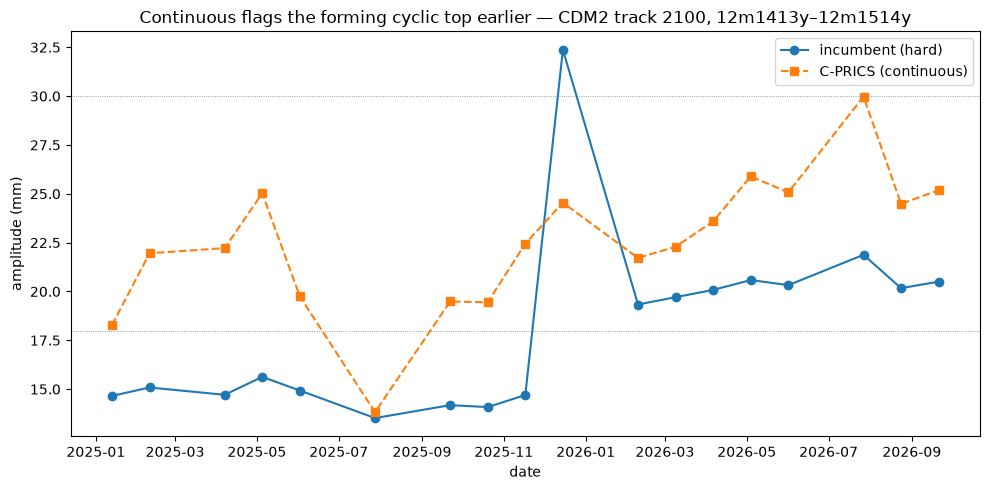

In [6]:
from cprics.location import to_mileage
site = earlier.sort_values("lead_days", ascending=False).site_id.iloc[0]
t = isl[isl.site_id == site].sort_values("date")
loc = f"{t.ELR.iloc[0]} track {t.TrackID.iloc[0]}, " \
      f"{to_mileage(t.start_location.iloc[0])}–{to_mileage(t.end_location.iloc[0])}"
print("This island is:", loc)
plt.figure(figsize=(10, 5))
plt.plot(t.date, t.hard_amplitude, "o-", label="incumbent (hard)")
plt.plot(t.date, t.amplitude, "s--", label="C-PRICS (continuous)")
for thr in (18, 30):
    plt.axhline(thr, ls=":", lw=0.6, color="grey")
plt.title(f"Continuous flags the forming cyclic top earlier — {loc}")
plt.ylabel("amplitude (mm)"); plt.xlabel("date"); plt.legend()
plt.tight_layout(); plt.show()

In [3]:
sm = isl.groupby("site_id").agg(cont_max=("amplitude","max"), hard_max=("hard_amplitude","max"))
flagged = sm[sm.cont_max >= 18]
print(f"continuous-flagged sites (>=18): {len(flagged)}")
print(f"  of which reach critical (hard>=30): {(flagged.hard_max>=30).sum()} "
      f"({100*(flagged.hard_max>=30).mean():.0f}%)")
print(f"base rate of critical among all tracked sites: {100*(sm.hard_max>=30).mean():.0f}%")

continuous-flagged sites (>=18): 124
  of which reach critical (hard>=30): 31 (25%)
base rate of critical among all tracked sites: 1%


In [4]:
from cprics.features import build_feature_table
from cprics.classify import FEATURES
feats = build_feature_table(isl, min_obs=3)        # features now on the continuous measure
print(feats[FEATURES].corr().round(2).to_string())

               current_amp  mean_amp  max_amp  volatility  slope_overall  slope_current  n_resets
current_amp           1.00      0.94     0.90        0.64           0.32           0.35     -0.12
mean_amp              0.94      1.00     0.97        0.73           0.12           0.27     -0.07
max_amp               0.90      0.97     1.00        0.86           0.09           0.32      0.00
volatility            0.64      0.73     0.86        1.00           0.02           0.45      0.14
slope_overall         0.32      0.12     0.09        0.02           1.00           0.18     -0.13
slope_current         0.35      0.27     0.32        0.45           0.18           1.00      0.07
n_resets             -0.12     -0.07     0.00        0.14          -0.13           0.07      1.00


In [7]:
from cprics.classify import cluster_sites, describe_clusters
LEAN = ["current_amp", "volatility", "slope_overall", "slope_current", "n_resets"]

real = isl.groupby("site_id")["amplitude"].max().ge(18)
real = real[real].index
feats_real = feats[feats.site_id.isin(real)].reset_index(drop=True)
print("genuine cyclic-top sites clustered:", len(feats_real))

clustered2, _ = cluster_sites(feats_real, n_clusters=4, features=LEAN)
reach = isl.groupby("site_id")["hard_amplitude"].max().ge(30).rename("reaches_I")
c2 = clustered2.merge(reach, on="site_id")
print(describe_clusters(clustered2, features=LEAN))
print("\nescalation by cluster:\n",
      c2.groupby("cluster")["reaches_I"].agg(["mean", "sum", "count"]).round(2).to_string())

genuine cyclic-top sites clustered: 91
         current_amp  volatility  slope_overall  slope_current  n_resets  \
cluster                                                                    
1              40.66       15.01           0.49          28.08      2.00   
2              53.40       11.87           4.42           4.42      0.00   
3              24.36        2.60           0.26           0.27      0.03   
4              15.50        5.99          -0.30           0.52      1.46   

         n_obs  
cluster         
1        12.00  
2         3.50  
3         9.82  
4        12.67  

escalation by cluster:
          mean  sum  count
cluster                  
1        1.00    2      2
2        0.50    1      2
3        0.18    7     39
4        0.25   12     48


In [9]:
feats = build_feature_table(isl, min_obs=3)          # rebuild with the robust slope
real = isl.groupby("site_id")["amplitude"].max().ge(18)
feats_real = feats[feats.site_id.isin(real[real].index)].reset_index(drop=True)

from cprics.classify import cluster_sites, describe_clusters, FEATURES
clustered3, _ = cluster_sites(feats_real, n_clusters=3, features=FEATURES)
reach = isl.groupby("site_id")["hard_amplitude"].max().ge(30).rename("reaches_I")
c3 = clustered3.merge(reach, on="site_id")
print(describe_clusters(clustered3))
print("\nescalation by cluster:\n",
      c3.groupby("cluster")["reaches_I"].agg(["mean", "sum", "count"]).round(2).to_string())

         current_amp  mean_amp  max_amp  volatility  slope_overall  \
cluster                                                              
1              17.31     18.03    23.80        3.60           0.11   
2              30.09     34.59    48.45        8.94          -0.54   
3              55.66     43.91    60.93       15.17           1.99   

         slope_current  n_resets  n_obs  
cluster                                  
1                 0.40      0.79  11.52  
2                 0.67      0.87  10.27  
3                20.39      1.33   9.00  

escalation by cluster:
          mean  sum  count
cluster                  
1        0.11    8     73
2        0.73   11     15
3        1.00    3      3


In [10]:
from cprics.classify import cluster_sites, describe_clusters
ACTIVE = ["current_amp", "slope_overall", "volatility", "n_resets"]
clustered4, _ = cluster_sites(feats_real, n_clusters=3, features=ACTIVE)
reach = isl.groupby("site_id")["hard_amplitude"].max().ge(30).rename("reaches_I")
c4 = clustered4.merge(reach, on="site_id")
print(describe_clusters(clustered4, features=ACTIVE))
print("\nescalation:\n",
      c4.groupby("cluster")["reaches_I"].agg(["mean", "sum", "count"]).round(2).to_string())

         current_amp  slope_overall  volatility  n_resets  n_obs
cluster                                                         
1              16.85          -0.25        6.31      1.47  12.71
2              24.11           0.26        2.55      0.00   9.66
3              53.40           4.42       11.87      0.00   3.50

escalation:
          mean  sum  count
cluster                  
1        0.27   14     51
2        0.18    7     38
3        0.50    1      2


In [12]:
import json
from cprics.classify import freeze_archetypes, assign_archetype

names = {1: "Saw-tooth", 2: "Steady climber", 3: "Severe"}   # from the table above
frozen = freeze_archetypes(clustered4, names)

(config.OUTPUTS_DIR / "models").mkdir(parents=True, exist_ok=True)
with open(config.OUTPUTS_DIR / "models" / "archetypes_9R.json", "w") as fh:
    json.dump(frozen, fh, indent=2)
print("frozen archetypes:", list(frozen["centroids"]))

# assign every tracked site, fast and deterministic
sf = build_feature_table(isl, min_obs=3).merge(
    isl.groupby("site_id")["amplitude"].max().rename("cont_max"), on="site_id")
sf["archetype"] = assign_archetype(sf, frozen)
print(sf["archetype"].value_counts().to_string())

frozen archetypes: ['Saw-tooth', 'Steady climber', 'Severe']
archetype
Dormant           2172
Saw-tooth           45
Steady climber      44
Severe               2
